# 9. Comparación de resultados y reflexión crítica

Este capítulo consolida los resultados y responde las preguntas de investigación **con los
números producidos por los capítulos anteriores**. Las respuestas de 9.3 se redactan
automáticamente a partir de esos números, con reglas explícitas (umbrales de significancia y de
magnitud). Son un borrador basado en evidencia: revíselas y complételas con su interpretación
antes de entregar.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else str(Path.cwd() / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from ctr.nbutils import setup, savefig, show, SERIES, FRAMEWORK_COLOR, MODEL_COLOR, MUTED
from ctr.bench import read_jsonl
from ctr import metrics as M

cfg, RES, FIG = setup()
runs = pd.concat([read_jsonl(RES / "runs_sklearn.jsonl"), read_jsonl(RES / "runs_spark.jsonl")], ignore_index=True)
omit = runs[runs["omitida"].notna()] if "omitida" in runs else runs.iloc[:0]
runs = runs[runs["omitida"].isna()] if "omitida" in runs else runs
runs["n"] = runs["n"].astype(int)
tests = pd.read_csv(RES / "pruebas_hipotesis.csv")
cruce = json.loads((RES / "punto_cruce.json").read_text())
amd = pd.read_csv(RES / "amdahl.csv") if (RES / "amdahl.csv").exists() else pd.DataFrame()
abl = pd.read_csv(RES / "tabla_ablaciones_sklearn.csv")
lime = pd.read_csv(RES / "lime_casos.csv"); lvs = pd.read_csv(RES / "lime_vs_shap.csv")
glob = pd.read_csv(RES / "coherencia_global.csv")
bench = read_jsonl(RES / "bench.jsonl")
bench_ok = bench[bench["fallo"].isna()] if "fallo" in bench else bench

Perfil: colab  |  resultados en: /content/deep-learning-01-ctr-mlp/results


## 9.1 Tabla comparativa final (por entorno, modelo y codificación)

In [2]:
MET = ["roc_auc", "pr_auc", "log_loss", "brier", "ece", "f1", "train_s", "predict_s", "train_peak_mb"]
final = M.summarize_runs(runs, ["framework", "model", "encoding", "n"], MET)
cols = ["framework", "model", "encoding", "n", "n_semillas"] + [f"{m}_media" for m in MET] + ["roc_auc_sd", "roc_auc_ic"]
final = final[cols].sort_values(["n", "framework", "encoding", "model"])
final.to_csv(RES / "tabla_final.csv", index=False)
show(final, 80)
if len(omit):
    print("Corridas omitidas por presupuesto de tiempo (también son evidencia de costo):")
    show(omit[["framework", "model", "encoding", "n", "motivo"]])

,framework,model,encoding,n,n_semillas,roc_auc_media,pr_auc_media,log_loss_media,brier_media,ece_media,f1_media,train_s_media,predict_s_media,train_peak_mb_media,roc_auc_sd,roc_auc_ic
0,sklearn,hgb,freq,100000,5,0.7128,0.3388,0.4132,0.1284,0.0066,0.3962,38.2304,9.6415,4470.8805,0.0000,"[0.7128, 0.7128]"
6,sklearn,mlp,freq,100000,5,0.6630,0.2903,0.4328,0.1336,0.0186,0.3472,14.3909,0.6720,4601.8891,0.0061,"[0.6554, 0.6705]"
15,sklearn,sgd,freq,100000,5,0.6541,0.2777,0.4333,0.1343,0.0190,0.3461,2.6407,0.1152,4247.4688,0.0027,"[0.6507, 0.6575]"
9,sklearn,mlp,hash,100000,5,0.7171,0.3460,0.4110,0.1278,0.0111,0.3914,37.1540,3.3859,5127.0188,0.0007,"[0.7162, 0.7180]"
18,sklearn,sgd,hash,100000,5,0.7166,0.3429,0.4134,0.1284,0.0184,0.3966,3.6984,0.1786,4756.3539,0.0024,"[0.7136, 0.7195]"
3,sklearn,hgb,target,100000,5,0.7204,0.3427,0.4096,0.1276,0.0074,0.4006,41.0711,4.5796,4410.3281,0.0000,"[0.7204, 0.7204]"
12,sklearn,mlp,target,100000,5,0.6861,0.3199,0.4220,0.1309,0.0128,0.3650,14.6136,0.6564,4506.8992,0.0070,"[0.6774, 0.6948]"
21,sklearn,sgd,target,100000,5,0.7121,0.3385,0.4137,0.1286,0.0142,0.3940,2.6400,0.1139,4184.1570,0.0007,"[0.7112, 0.7130]"
24,spark,gbt,freq,100000,1,0.6969,0.3298,0.4196,0.1299,0.0135,0.3859,20.9529,8.5739,29098.5625,NaN,n=1
27,spark,lr,freq,100000,1,0.6563,0.2775,0.4326,0.1341,0.0175,0.3504,2.3393,6.1751,27817.2500,NaN,n=1


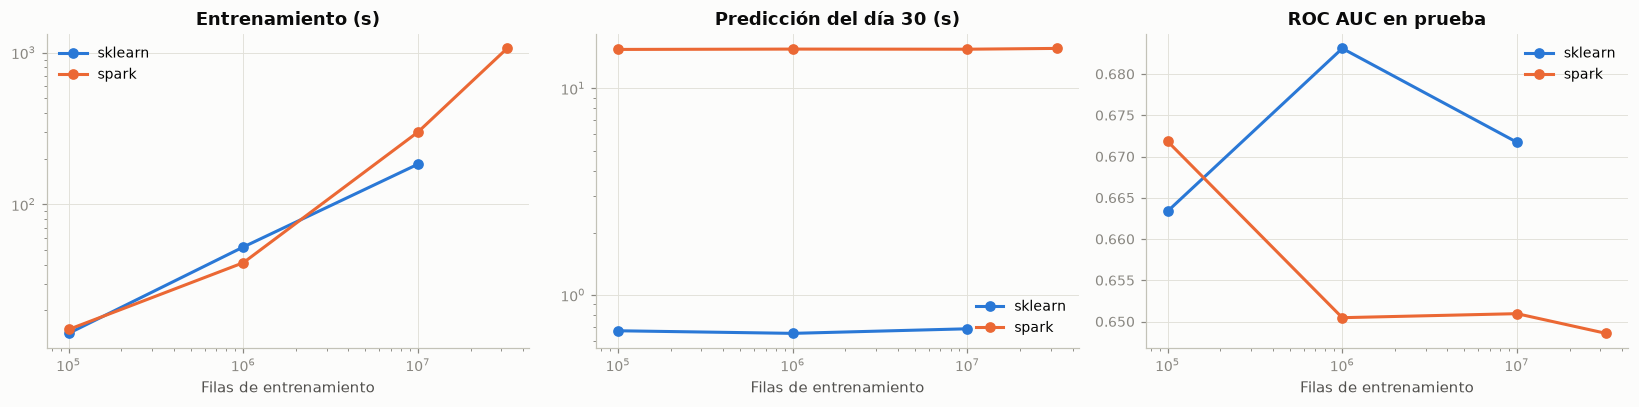

In [3]:
# tiempos de entrenamiento y predicción del MLP por entorno y tamaño (codificación por frecuencia)
g = runs[(runs.model == "mlp") & (runs.encoding == "freq")].groupby(["framework", "n"])[["train_s", "predict_s", "roc_auc"]].median().reset_index()
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for fw, gg in g.groupby("framework"):
    for ax, c in zip(axs, ["train_s", "predict_s", "roc_auc"]):
        ax.plot(gg["n"], gg[c], marker="o", color=FRAMEWORK_COLOR[fw], label=fw)
for ax, t in zip(axs, ["Entrenamiento (s)", "Predicción del día 30 (s)", "ROC AUC en prueba"]):
    ax.set_xscale("log"); ax.set_title(t); ax.set_xlabel("Filas de entrenamiento"); ax.legend()
axs[0].set_yscale("log"); axs[1].set_yscale("log")
savefig(fig, FIG, "09_mlp_entornos")

## 9.2 Ablaciones (scikit-learn)

In [4]:
show(abl[["factor", "nivel", "n_semillas", "roc_auc_media", "roc_auc_sd", "log_loss_media", "ece_media", "f1_media", "train_s_media"]], 40)

,factor,nivel,n_semillas,roc_auc_media,roc_auc_sd,log_loss_media,ece_media,f1_media,train_s_media
0,arquitectura,100,3,0.7295,0.0002,0.4064,0.0084,0.4093,63.2296
1,arquitectura,100-50,3,0.7292,0.0012,0.4067,0.0093,0.4089,49.9558
2,arquitectura,256-128,3,0.7287,0.0012,0.4068,0.0091,0.4076,99.9794
3,arquitectura,50,3,0.7284,0.0002,0.4068,0.0080,0.4077,38.1482
4,cruces,con cruces,3,0.7312,0.0001,0.4056,0.0075,0.4112,57.9800
5,cruces,sin cruces,3,0.7295,0.0002,0.4064,0.0084,0.4093,64.7425
6,dimension_hashing,2^12,3,0.7269,0.0012,0.4077,0.0092,0.4071,33.6252
7,dimension_hashing,2^14,3,0.7295,0.0002,0.4064,0.0084,0.4093,63.1724
8,dimension_hashing,2^16,3,0.7276,0.0010,0.4069,0.0072,0.4070,156.3960
9,parada_temprana,interna aleatoria (enunciado),3,0.7280,0.0012,0.4068,0.0081,0.4078,44.2227


## 9.3 Respuestas a las preguntas de investigación (borrador generado desde los resultados)

In [5]:
def fmt(x, d=4):
    return "—" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:,.{d}f}"

out = []
# ---------- P1
cr = (bench_ok[bench_ok.exp == "cruce"].groupby(["framework", "n"])[["train_s", "total_s", "roc_auc"]].median().reset_index()
      if len(bench_ok) else pd.DataFrame())
if cruce.get("train_s"):
    p1 = (f"Se observó un punto de cruce en entrenamiento alrededor de **{cruce['train_s']:,.0f} filas**"
          + (f" y extremo a extremo alrededor de **{cruce['total_s']:,.0f} filas**." if cruce.get("total_s") else
             "; extremo a extremo, sin embargo, Spark no llegó a superar a scikit-learn en el rango medido (la lectura y el preprocesamiento pesan)."))
    p1 += " **H1 se sostiene** en el rango medido."
else:
    p1 = ("En el rango medido **no se observó punto de cruce**: scikit-learn fue más rápido en todos los volúmenes "
          "en una sola máquina. **H1 se sostiene solo en su segunda parte** (por debajo del cruce scikit-learn es más eficiente); "
          "el cruce, si existe, está por encima del volumen probado o requiere un clúster real.")
if len(cr):
    q = cr.pivot(index="n", columns="framework", values="roc_auc")
    if {"sklearn", "spark"} <= set(q.columns):
        p1 += f" La AUC de la carga fija fue {fmt(q['sklearn'].mean())} (scikit-learn) vs {fmt(q['spark'].mean())} (Spark) en promedio sobre los tamaños."
if len(amd):
    p1 += " Fracción secuencial de Amdahl: " + "; ".join(f"{r.framework} s = {r.fraccion_secuencial:.2f} (aceleración máxima teórica ≈ {r.aceleracion_max_teorica:.1f}×)" for r in amd.itertuples()) + "."
out.append("**P1. ¿A partir de qué volumen PySpark supera a scikit-learn en tiempo sin degradar la calidad?**\n\n" + p1)

# ---------- P2
sk = runs[(runs.framework == "sklearn") & (runs.model == "mlp")]
nn = sk.groupby("n")["encoding"].nunique()
n2 = int(nn[nn == nn.max()].index.max())
e2 = sk[sk.n == n2].groupby("encoding")[["roc_auc", "log_loss", "train_s", "train_peak_mb"]].mean()
prep = pd.read_csv(RES / "prep_codificaciones.csv")
p2 = f"Con n = {n2:,}, MLP: " + "; ".join(f"{e}: AUC {fmt(r.roc_auc)}, log loss {fmt(r.log_loss)}, entrenamiento {fmt(r.train_s,1)} s" for e, r in e2.iterrows()) + ". "
p2 += "Memoria de la matriz de entrada: " + "; ".join(f"{r.codificacion}: {r.MB_matriz:,.0f} MB" for r in prep.itertuples()) + ". "
if {"hash", "freq"} <= set(e2.index):
    d = e2.loc["hash", "roc_auc"] - e2.loc["freq", "roc_auc"]
    mem_h = prep[prep.codificacion.str.startswith("hash")]["MB_matriz"].median(); mem_f = prep[prep.codificacion == "freq"]["MB_matriz"].iloc[0]
    if abs(d) < 0.005:
        p2 += f"Hashing y frecuencia quedan a menos de 0,005 de AUC (Δ = {d:+.4f}), con memorias de {mem_h:,.0f} vs {mem_f:,.0f} MB: **H2 se sostiene**."
    else:
        p2 += (f"La diferencia de AUC hashing − frecuencia es {d:+.4f}: **H2 no se sostiene tal como está formulada**; "
               + ("el hashing es claramente mejor, pero ocupa más memoria que la frecuencia (la hipótesis suponía lo contrario)." if d > 0 and mem_h > mem_f
                  else "conviene reformularla según el sentido de la diferencia y el costo en memoria medido."))
hd = abl[abl.factor == "dimension_hashing"]
if len(hd):
    p2 += " Dimensión del hashing (ablación): " + "; ".join(f"{r.nivel}: AUC {fmt(r.roc_auc_media)}" for r in hd.itertuples()) + "."
out.append("**P2. ¿Cómo afecta la codificación de alta cardinalidad al desempeño y al costo?**\n\n" + p2)

# ---------- P3
p3 = []
for r in tests.itertuples():
    sig = r.p_DeLong_Holm < 0.05
    p3.append(f"{r.A} vs {r.B}: ΔAUC = {r.dif_AUC:+.4f} (p Holm = {r.p_DeLong_Holm:.2g}) → "
              + ("diferencia significativa" if sig else "sin diferencia significativa")
              + (", pero de magnitud pequeña (< 0,005)" if sig and abs(r.dif_AUC) < 0.005 else ""))
out.append("**P3. ¿Aporta el MLP una mejora significativa sobre líneas base más simples?**\n\n- " + "\n- ".join(p3))

# ---------- P4
p4 = (f"Fidelidad media de LIME: R² = {lime.R2_medio.mean():.3f} (mínimo {lime.R2_min.min():.3f}). "
      f"Estabilidad entre semillas: Jaccard medio del top-{cfg['explain']['top_k']} = {lime.jaccard_topk_entre_semillas.mean():.3f}. "
      f"Acuerdo con SHAP: Jaccard {lvs.jaccard_topk.mean():.3f}, Spearman {lvs.spearman_abs.mean():.3f}. ")
rho = glob[["LIME_|w|_medio", "SHAP_|phi|_medio", "caida_auc_media"]].corr(method="spearman")
p4 += f"Coherencia global (Spearman de rankings): LIME–permutación {rho.iloc[0, 2]:.2f}, SHAP–permutación {rho.iloc[1, 2]:.2f}. "
p4 += ("Las explicaciones son **estables y razonablemente fieles**." if lime.R2_medio.mean() > 0.5 and lime.jaccard_topk_entre_semillas.mean() > 0.7
       else "Las explicaciones **no son suficientemente estables o fieles** para tomarlas como evidencia por sí solas: deben contrastarse con SHAP y con la importancia global.")
out.append("**P4. ¿Son las explicaciones de LIME estables y fieles al modelo?**\n\n" + p4)
display(Markdown("\n\n".join(out)))
(RES / "respuestas_borrador.md").write_text("\n\n".join(out), encoding="utf8")

**P1. ¿A partir de qué volumen PySpark supera a scikit-learn en tiempo sin degradar la calidad?**

En el rango medido **no se observó punto de cruce**: scikit-learn fue más rápido en todos los volúmenes en una sola máquina. **H1 se sostiene solo en su segunda parte** (por debajo del cruce scikit-learn es más eficiente); el cruce, si existe, está por encima del volumen probado o requiere un clúster real. La AUC de la carga fija fue 0.6683 (scikit-learn) vs 0.6660 (Spark) en promedio sobre los tamaños. Fracción secuencial de Amdahl: sklearn s = 1.00 (aceleración máxima teórica ≈ 1.0×); spark s = 0.21 (aceleración máxima teórica ≈ 4.9×).

**P2. ¿Cómo afecta la codificación de alta cardinalidad al desempeño y al costo?**

Con n = 10,000,000, MLP: freq: AUC 0.6717, log loss 0.4401, entrenamiento 184.0 s; hash: AUC 0.7422, log loss 0.3999, entrenamiento 1,337.4 s; target: AUC 0.7253, log loss 0.4086, entrenamiento 437.3 s. Memoria de la matriz de entrada: hash 2^12: 56 MB; hash 2^14: 56 MB; hash 2^16: 56 MB; freq: 27 MB; target: 27 MB. La diferencia de AUC hashing − frecuencia es +0.0705: **H2 no se sostiene tal como está formulada**; el hashing es claramente mejor, pero ocupa más memoria que la frecuencia (la hipótesis suponía lo contrario). Dimensión del hashing (ablación): 2^12: AUC 0.7269; 2^14: AUC 0.7295; 2^16: AUC 0.7276.

**P3. ¿Aporta el MLP una mejora significativa sobre líneas base más simples?**

- sk MLP freq vs spark MLP freq: ΔAUC = +0.0208 (p Holm = 0) → diferencia significativa
- sk MLP freq vs sk HGB freq: ΔAUC = -0.0534 (p Holm = 0) → diferencia significativa
- sk MLP freq vs sk SGD freq: ΔAUC = +0.0308 (p Holm = 0) → diferencia significativa
- spark MLP freq vs spark GBT freq: ΔAUC = -0.0528 (p Holm = 0) → diferencia significativa
- spark MLP freq vs spark LR freq: ΔAUC = +0.0157 (p Holm = 0) → diferencia significativa
- sk MLP hash vs sk HGB target: ΔAUC = +0.0031 (p Holm = 1.9e-100) → diferencia significativa, pero de magnitud pequeña (< 0,005)
- sk MLP hash vs sk SGD hash: ΔAUC = +0.0105 (p Holm = 0) → diferencia significativa
- sk MLP hash vs sk MLP freq: ΔAUC = +0.0705 (p Holm = 0) → diferencia significativa
- spark MLP hash vs spark LR hash: ΔAUC = +0.0083 (p Holm = 0) → diferencia significativa
- sk MLP hash (mismo n que Spark) vs spark MLP hash: ΔAUC = -0.0002 (p Holm = 0.016) → diferencia significativa, pero de magnitud pequeña (< 0,005)

**P4. ¿Son las explicaciones de LIME estables y fieles al modelo?**

Fidelidad media de LIME: R² = 0.118 (mínimo 0.069). Estabilidad entre semillas: Jaccard medio del top-5 = 0.777. Acuerdo con SHAP: Jaccard 0.595, Spearman 0.698. Coherencia global (Spearman de rankings): LIME–permutación 0.49, SHAP–permutación 0.48. Las explicaciones **no son suficientemente estables o fieles** para tomarlas como evidencia por sí solas: deben contrastarse con SHAP y con la importancia global.

2885

## 9.4 Reflexión crítica

Responda cada punto citando los números de las tablas anteriores (los borradores de 9.3 son el
punto de partida).

1. **¿Qué entorno fue más rápido, en qué rango de volumen y por qué?** Considere: costo fijo de
   arrancar la JVM y planificar trabajos; serialización Python ↔ JVM; que un `.gz` no es divisible
   (una sola tarea de lectura); que en una sola máquina Spark compite por los mismos núcleos y
   memoria; la densificación del MLP de MLlib frente al producto disperso de scikit-learn.
2. **¿Cuál fue más preciso y mejor calibrado, y es significativa la diferencia?** Use la tabla
   6.5 (DeLong/McNemar con Holm), los IC por bootstrap y las curvas de calibración. Recuerde que con
   millones de filas casi todo es "significativo": discuta la magnitud.
3. **¿Cuándo se justifica PySpark y cuándo es sobrecosto?** Datos que no caben en una máquina,
   tolerancia a fallos, integración con un lago de datos y pipelines programados, frente a la
   simplicidad y velocidad de scikit-learn mientras los datos caben en RAM.
4. **Limitaciones arquitectónicas del MLP nativo de Spark** frente a una red con embeddings
   (capítulo 5.6): sin embeddings, sin dropout ni L2, sigmoide fija, entrada densa, solo l-bfgs/gd.
5. **¿Qué aporta LIME, qué no garantiza y cómo se compara con SHAP?** (capítulo 8.5 y P4).

### Amenazas a la validez

- **Deriva temporal:** el PSI del capítulo 2 mide cuánto cambia la distribución entre los días
  21–28 y el 30; una sola ventana de prueba (un día) no permite generalizar a otras semanas.
- **Fuga de información:** controlada con división temporal, ajuste de vocabularios, escaladores y
  codificadores solo con entrenamiento, target encoding out-of-fold y umbral elegido en
  validación. Riesgo residual: el cross-fitting del `TargetEncoder` es aleatorio **dentro** de
  los días de entrenamiento.
- **Anonimización:** C1 y C14–C21 no tienen semántica conocida; las explicaciones sobre ellas
  no se pueden interpretar en términos de negocio.
- **Sesgo de muestreo:** Avazu es una muestra de 2014 de una sola plataforma; el submuestreo por
  hash es uniforme, pero las muestras de 100 mil no representan bien las categorías raras.
- **Recursos de cómputo:** con el perfil `mac8` (Mac de 8 GB) los tamaños llegan a 3 M de filas y no
  se usa el entrenamiento completo; el punto de cruce de P1 solo puede afirmarse dentro de ese rango.
- **Validez del benchmark:** una sola máquina (Spark en modo local), carga de otros procesos,
  caché del sistema de archivos y número de repeticiones limitado.
- **Diferencias de implementación:** los hashers de scikit-learn y Spark usan semillas distintas
  (mismos principios, índices diferentes) y los MLP difieren en activación y optimizador, de modo
  que "scikit-learn vs Spark" compara implementaciones completas, no solo motores de cómputo.